# Car Market Explorer Project

## 1.Import and overview

In [1]:
import pandas as pd
import plotly.express as px
import streamlit as st


- We need to make sure that everything is alright in this DataBase.

In [2]:
vehicles_df = pd.read_csv('../vehicles.csv')
print(vehicles_df.sample(5))
print()
vehicles_df.info()

       price  model_year                     model  condition  cylinders fuel  \
7649   29900      2018.0  chevrolet silverado 1500       good        8.0  gas   
29927   4000      2008.0            subaru outback  excellent        4.0  gas   
20134   5450      2010.0             ford explorer       good        NaN  gas   
33384  14800         NaN        chevrolet corvette  excellent        8.0  gas   
46754  22500      2012.0                ford f-150  excellent        8.0  gas   

       odometer transmission         type paint_color  is_4wd date_posted  \
7649    72677.0    automatic        truck       white     1.0  2019-02-10   
29927  190500.0       manual        wagon        blue     1.0  2019-03-04   
20134       NaN    automatic          SUV         red     NaN  2018-09-23   
33384   73276.0    automatic  convertible         NaN     NaN  2018-07-06   
46754   66800.0    automatic        truck         red     1.0  2018-11-22   

       days_listed  
7649            12  
29927   

## 2. Data Cleaning

#### Our initial check showed some issues that need to be fixed:

1. Convert `date_posted` to datetime;
2. Standardize the text columns `model`, `condition`, `fuel`, `transmission`, `type` and `paint_color` (remove extra spaces, lowercase);
3. Check for fully duplicated rows and remove them;
4. Handle missing values in `paint_color`, `is_4wd`, `model_year`, `cylinders` and `odometer`:
   * `paint_color`: fill with "unknown";
   * `is_4wd`: it only holds 1.0 or NaN, so NaN means the car is not 4WD. Fill with 0 and convert to boolean;
   * `model_year` and `odometer`: fill with the median of similar vehicles instead of the overall median;
   * `cylinders`: fill with the mode of the same model, since it holds fixed values;
5. Convert `model_year` and `cylinders` to int64 only after their missing values are filled, since int64 does not accept NaN;
6. Remove outliers in `price`, `odometer` and `model_year`, using cutoffs chosen from cumulative curves;
7. Split the vehicle name into three columns: `car_name` (full name), `brand` and `model`, to be used as filters in the app.

In [3]:
# Check for fully duplicated rows and remove them.
print(vehicles_df.duplicated().sum())
vehicles_df = vehicles_df.drop_duplicates().reset_index(drop=True)



0


In [4]:
# Standarize text columns and fill the missing values.
for col in ['model', 'condition', 'fuel', 'transmission', 'type', 'paint_color']:
    vehicles_df[col] = vehicles_df[col].str.strip().str.lower()

vehicles_df['date_posted'] = pd.to_datetime(vehicles_df['date_posted'],format='%Y-%m-%d')
vehicles_df['paint_color'] = vehicles_df['paint_color'].fillna('unknown')
vehicles_df['is_4wd'] = vehicles_df['is_4wd'].fillna(0).astype(bool)

In [5]:
# Fill the missing values with the median.
vehicles_df['model_year'] = vehicles_df['model_year'].fillna(
    vehicles_df.groupby('model')['model_year'].transform('median'))

def get_mode(x):
    return x.mode()[0]
vehicles_df['cylinders'] = vehicles_df['cylinders'].fillna(
    vehicles_df.groupby('model')['cylinders'].transform(get_mode))
# For cylinders we are fullfilling with the 'mode' instead of 'median'.

vehicles_df['odometer'] = vehicles_df['odometer'].fillna(
    vehicles_df.groupby(['model','condition','model_year'])['model_year'].transform('median'))

# To verify if our treatment got right.
vehicles_df.isna().sum()

price           0
model_year      0
model           0
condition       0
cylinders       0
fuel            0
odometer        0
transmission    0
type            0
paint_color     0
is_4wd          0
date_posted     0
days_listed     0
dtype: int64

In [6]:
# Convert 'model_year' Dtype to the right one.
vehicles_df['model_year'] = vehicles_df['model_year'].astype('int')
vehicles_df['cylinders'] = vehicles_df['cylinders'].astype('int')
vehicles_df['odometer'] = vehicles_df['odometer'].astype('int')

In [7]:
# Now we check the outliers on Data Frame:
print(vehicles_df.describe())
print()
print(len(vehicles_df))

               price    model_year     cylinders       odometer  \
count   51525.000000  51525.000000  51525.000000   51525.000000   
mean    12132.464920   2009.793557      6.121494   98162.169122   
min         1.000000   1908.000000      3.000000       0.000000   
25%      5000.000000   2007.000000      4.000000   35896.000000   
50%      9000.000000   2011.000000      6.000000   99114.000000   
75%     16839.000000   2014.000000      8.000000  146541.000000   
max    375000.000000   2019.000000     12.000000  990000.000000   
std     10040.803015      6.099381      1.657296   72529.443505   

                      date_posted  days_listed  
count                       51525  51525.00000  
mean   2018-10-25 01:57:46.270742     39.55476  
min           2018-05-01 00:00:00      0.00000  
25%           2018-07-29 00:00:00     19.00000  
50%           2018-10-25 00:00:00     33.00000  
75%           2019-01-21 00:00:00     53.00000  
max           2019-04-19 00:00:00    271.00000  
std 

#### Our suspects were right, we have outliers in "price", "odometer" and "model_year", now we need to correct it.

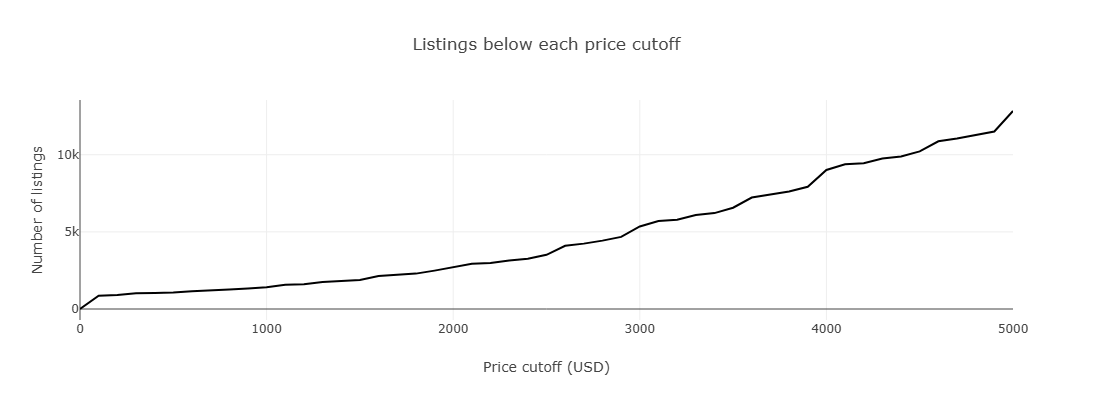

In [8]:
# Count how many listings fall below each candidate price cutoff.

cutoffs = range(0, 5001, 100)

px.line(
    x=cutoffs,
    y=[(vehicles_df['price'] < c).sum() for c in cutoffs],
    title='Listings below each price cutoff',
    labels={'x': 'Price cutoff (USD)', 'y': 'Number of listings'},
    width=700,
    height=400
)

In [9]:
(vehicles_df['price'] < 100).sum()

np.int64(863)

#### The graph shows that the values stabilized after the limit reached 100 USD, so that will be our cutoff. Removing listings below this value drops only 863 rows (about 1,6% of the data).

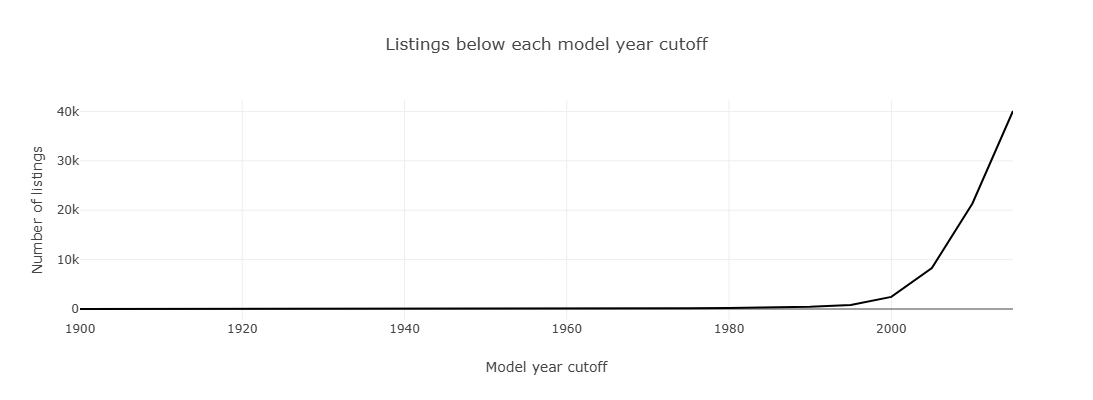

In [10]:
# Count how many listings have a model year below each candidate cutoff.
cutoffs = range(1900, 2018, 5)

px.line(
    x=cutoffs,
    y=[(vehicles_df['model_year'] < c).sum() for c in cutoffs],
    title='Listings below each model year cutoff',
    labels={'x': 'Model year cutoff', 'y': 'Number of listings'},
    width=700,
    height=400
)

In [11]:
(vehicles_df['model_year'] < 1975).sum()

np.int64(134)

#### The graph shows that the curve only rises sharply from the 90s onward, so we chose a more conservative cutoff of 1975 to keep older but plausible listings. Removing listings older than this year drops only 135 rows (about 0.26% of the data).

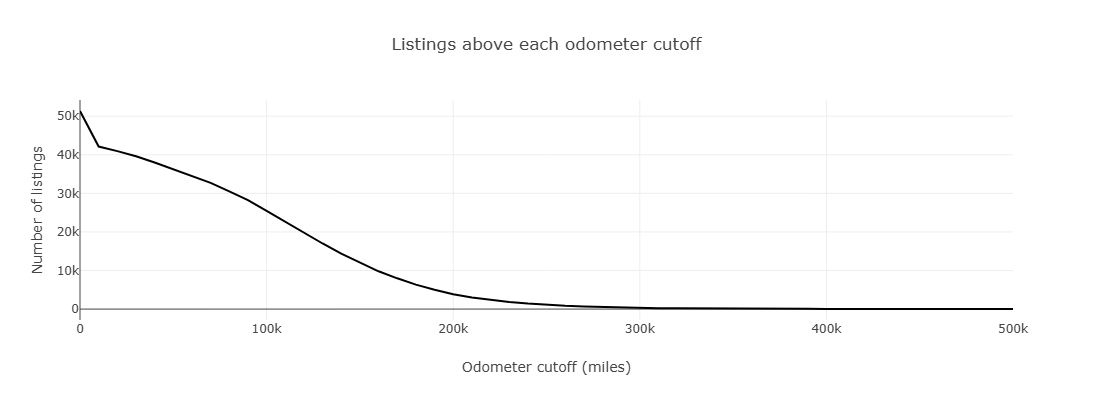

In [12]:
# Count how many listings have an odometer above each candidate cutoff.
cutoffs = range(0, 500001, 10000)

px.line(
    x=cutoffs,
    y=[(vehicles_df['odometer'] > c).sum() for c in cutoffs],
    title='Listings above each odometer cutoff',
    labels={'x': 'Odometer cutoff (miles)', 'y': 'Number of listings'},
    width=700,
    height=400
)

In [13]:
print((vehicles_df['odometer'] > 300000).sum())

287


#### The graph shows that the curve flattens out at around 300k miles, so that will be our cutoff. Removing listings above this value drops only 287 rows (about 0.56% of the data).

In [14]:
# Remove the outliers.

MIN_PRICE = 100
MIN_YEAR = 1975
MAX_ODOMETER = 300000

vehicles_df = vehicles_df[
    (vehicles_df['price'] >= MIN_PRICE) &
    (vehicles_df['model_year'] >= MIN_YEAR) &
    (vehicles_df['odometer'] <= MAX_ODOMETER)
].reset_index(drop=True)

In [15]:
# Create columns that will help us in our Dashboard.
vehicles_df = vehicles_df.rename(columns={'model': 'car_name'})
vehicles_df['brand'] = vehicles_df['car_name'].str.split().str[0]
vehicles_df['model'] = vehicles_df['car_name'].str.split(n=1).str[1]
vehicles_df['brand'].value_counts()

brand
ford             12384
chevrolet        10324
toyota            5301
honda             3409
jeep              3185
ram               3150
nissan            3139
gmc               2325
subaru            1269
hyundai           1170
dodge             1170
volkswagen         862
chrysler           834
kia                585
cadillac           321
buick              271
bmw                267
acura              236
mercedes-benz       41
Name: count, dtype: int64

In [16]:
print(vehicles_df.sample(5))
vehicles_df.info()

       price  model_year                    car_name  condition  cylinders  \
10631  13990        2005               toyota tundra       good          8   
10445   9800        2008                   gmc yukon       good          8   
33334   9200        2014             chevrolet cruze   like new          4   
32101  12497        2010                  ford f-150  excellent          8   
37477  17000        2008  chevrolet silverado 2500hd  excellent          8   

      fuel  odometer transmission    type paint_color  is_4wd date_posted  \
10631  gas      2005    automatic   truck       white    True  2019-03-18   
10445  gas    280000    automatic     suv       white   False  2018-08-28   
33334  gas     63000    automatic   sedan       white   False  2018-09-28   
32101  gas    101291    automatic  pickup        grey    True  2018-12-12   
37477  gas    116000    automatic   truck        grey    True  2019-03-05   

       days_listed      brand             model  
10631           57

### Conclusion item 1

The dataset is now clean and ready to power the app. Missing values were filled with the median of similar vehicles (or the most common value, in the case of `cylinders`), and the remaining columns were handled according to what they represent: a missing color became "unknown", and a missing `is_4wd` meant the car simply isn't 4WD. No duplicated rows were found, and all text columns were standardized.

To keep the analysis reliable, I removed outliers using cutoffs chosen from cumulative curves rather than guesswork: listings priced below 100 USD (863 rows), with more than 300k miles (287 rows) or older than 1975 (135 rows). Together, these cuts leave a final dataset of X rows, down from 51,525.

Finally, I split the vehicle name into `car_name`, `brand` and `model`. This will make it possible to filter by brand and to rank the most listed cars in the dashboard.

## 3. Data Test 